# Logprob Metric Distributions

Visualize scalar logprob metrics for each dataset/model experiment and HG/MG split. The notebook reads existing metric outputs from `TEXT_DETECTION_DATA/processed/{dataset}__{model}/{split}/metrics/metrics.parquet`.

In [9]:
from __future__ import annotations

import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from tqdm.auto import tqdm

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)

## Load Metrics

Set `TEXT_DETECTION_DATA` before opening the notebook, or edit `DATA_ROOT` below for local exploration.

In [2]:
DATA_ROOT = Path(os.environ.get("TEXT_DETECTION_DATA", "D:/Projects/master_diploma/text-detection-data"))
PROCESSED_ROOT = DATA_ROOT / "processed"

def parse_experiment_name(experiment_name: str) -> tuple[str, str]:
    if "__" not in experiment_name:
        return experiment_name, "unknown"
    dataset, model = experiment_name.split("__", maxsplit=1)
    return dataset, model

def discover_metric_files(processed_root: Path) -> list[Path]:
    return sorted(processed_root.glob("*/*/metrics/metrics.parquet"))

def load_metrics(processed_root: Path) -> pd.DataFrame:
    frames = []
    for path in discover_metric_files(processed_root):
        experiment_name = path.parents[2].name
        split = path.parents[1].name
        dataset, model = parse_experiment_name(experiment_name)
        frame = pd.read_parquet(path)
        frame.insert(0, "dataset", dataset)
        frame.insert(1, "model", model)
        frame.insert(2, "experiment_name", experiment_name)
        frame["split"] = frame.get("split", split).fillna(split)
        frame["metrics_path"] = str(path)
        frames.append(frame)
    if not frames:
        raise FileNotFoundError(f"No metrics files found under {processed_root}")
    return pd.concat(frames, ignore_index=True)

metrics_df = load_metrics(PROCESSED_ROOT)
metrics_df.head()

,dataset,model,experiment_name,id,split,perplexity,prompt_mu_score,prompt_sigma_score,num_tokens,metrics_version,processed_at,text_len_symbols,text_len_words,text_len_sentences,metrics_path
0,kaggle_train,opt_350m,kaggle_train__opt_350m,749,HG,26.954962,-3.294167,3.166986,695,logprob_metrics_v1,2026-07-14T22:35:43.234980+00:00,3289,584,23,D:\Projects\master_diploma\text-detection-data...
1,kaggle_train,opt_350m,kaggle_train__opt_350m,750,HG,30.361107,-3.413162,3.203034,568,logprob_metrics_v1,2026-07-14T22:35:43.237623+00:00,2738,462,27,D:\Projects\master_diploma\text-detection-data...
2,kaggle_train,opt_350m,kaggle_train__opt_350m,751,HG,29.600173,-3.387780,3.027581,896,logprob_metrics_v1,2026-07-14T22:35:43.237623+00:00,4428,744,48,D:\Projects\master_diploma\text-detection-data...
3,kaggle_train,opt_350m,kaggle_train__opt_350m,752,HG,31.237218,-3.441610,3.013686,838,logprob_metrics_v1,2026-07-14T22:35:43.237623+00:00,4013,686,43,D:\Projects\master_diploma\text-detection-data...
4,kaggle_train,opt_350m,kaggle_train__opt_350m,753,HG,35.693755,-3.574976,3.259712,1081,logprob_metrics_v1,2026-07-14T22:35:43.237623+00:00,4698,871,49,D:\Projects\master_diploma\text-detection-data...


In [3]:
summary = (
    metrics_df.groupby(["dataset", "model", "split"], dropna=False)
    .size()
    .rename("rows")
    .reset_index()
    .sort_values(["dataset", "model", "split"])
)
summary

,dataset,model,split,rows
0,kaggle_train,opt_350m,HG,570
1,kaggle_train,opt_350m,MG,570
2,kaggle_train,smollm2_360m,HG,1240
3,kaggle_train,smollm2_360m,MG,1240


## Configure Experiment Filters

Leave `selected_datasets` or `selected_models` as `None` to include everything currently available.

In [4]:
available_metrics = [
    "prompt_mu_score",
    "prompt_sigma_score",
    "perplexity",
    "num_tokens",
    "text_len_symbols",
    "text_len_words",
    "text_len_sentences",
]
available_metrics = [metric for metric in available_metrics if metric in metrics_df.columns]

selected_datasets = None
selected_models = None
selected_metrics = [
    "prompt_mu_score",
    "prompt_sigma_score",
    "perplexity",
    "num_tokens",
    "text_len_words",
]
selected_metrics = [metric for metric in selected_metrics if metric in available_metrics]

plot_df = metrics_df.copy()
if selected_datasets is not None:
    plot_df = plot_df[plot_df["dataset"].isin(selected_datasets)]
if selected_models is not None:
    plot_df = plot_df[plot_df["model"].isin(selected_models)]

print(f"Rows selected: {len(plot_df):,}")
print(f"Datasets: {sorted(plot_df['dataset'].unique())}")
print(f"Models: {sorted(plot_df['model'].unique())}")
print(f"Metrics: {selected_metrics}")

Rows selected: 3,620
Datasets: ['kaggle_train']
Models: ['opt_350m', 'smollm2_360m']
Metrics: ['prompt_mu_score', 'prompt_sigma_score', 'perplexity', 'num_tokens', 'text_len_words']


## Distribution Helpers

In [5]:
def plot_metric_distributions(data: pd.DataFrame, metric: str, *, bins: int = 50) -> None:
    grid = sns.displot(
        data=data,
        x=metric,
        hue="split",
        row="dataset",
        col="model",
        kind="hist",
        bins=bins,
        stat="density",
        common_norm=False,
        element="step",
        height=3.0,
        aspect=1.25,
        facet_kws={"sharex": False, "sharey": False},
    )
    grid.set_titles(row_template="{row_name}", col_template="{col_name}")
    grid.set_axis_labels(metric, "density")
    grid.figure.suptitle(f"Distribution of {metric} by dataset/model/split", y=1.03)
    plt.show()

def plot_experiment_metric_row(data: pd.DataFrame, dataset: str, model: str, metrics: list[str]) -> None:
    experiment_df = data[(data["dataset"] == dataset) & (data["model"] == model)]
    if experiment_df.empty:
        raise ValueError(f"No rows for dataset={dataset!r}, model={model!r}")

    fig, axes = plt.subplots(1, len(metrics), figsize=(4.2 * len(metrics), 3.5), constrained_layout=True)
    if len(metrics) == 1:
        axes = [axes]
    for axis, metric in zip(axes, metrics):
        sns.histplot(
            data=experiment_df,
            x=metric,
            hue="split",
            bins=50,
            stat="density",
            common_norm=False,
            element="step",
            ax=axis,
        )
        axis.set_title(metric)
        axis.set_ylabel("density")
    fig.suptitle(f"{dataset} / {model}", y=1.08)
    plt.show()

## Compare One Metric Across All Experiments

This view is useful for quickly scanning whether HG and MG distributions separate consistently across datasets and LLMs.

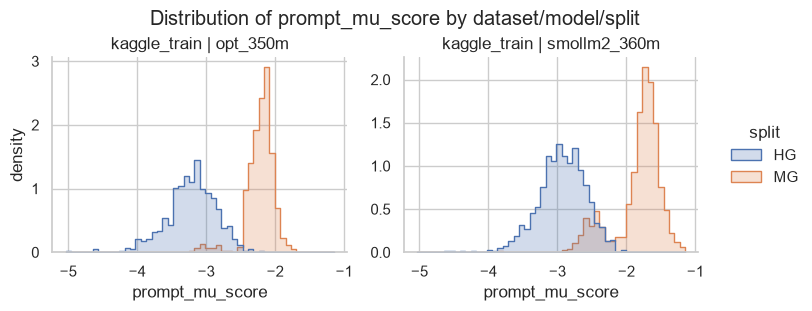

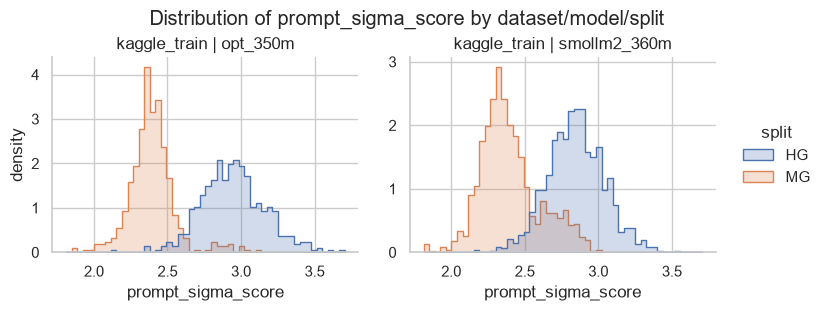

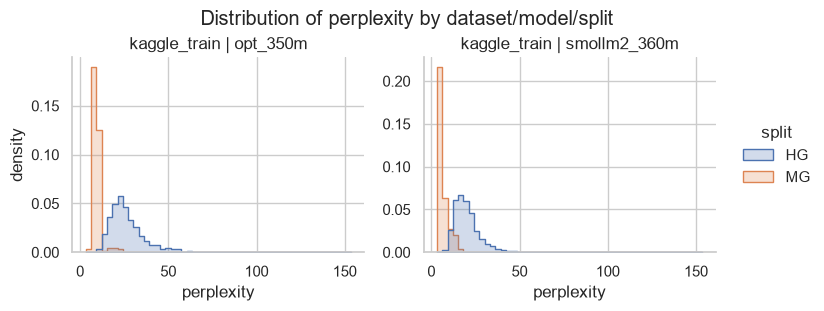

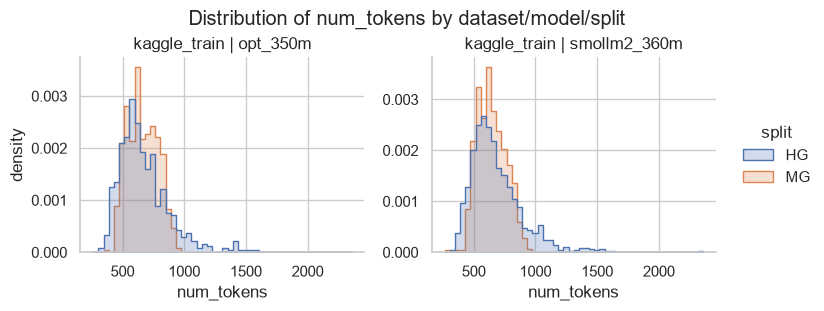

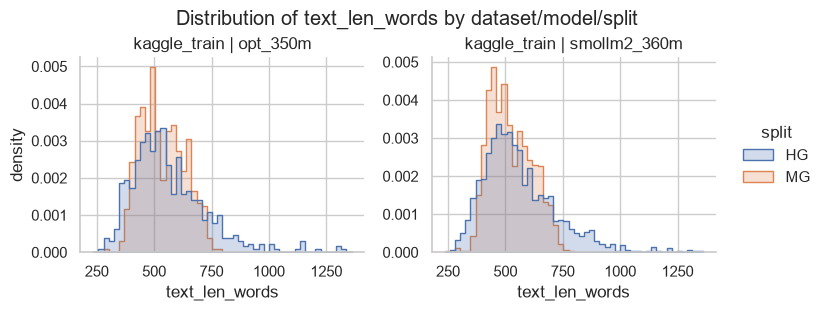

In [6]:
for metric in selected_metrics:
    plot_metric_distributions(plot_df, metric)

## Inspect Each Dataset/Model Combination

This produces one image per experiment with the selected metrics arranged in a single row.

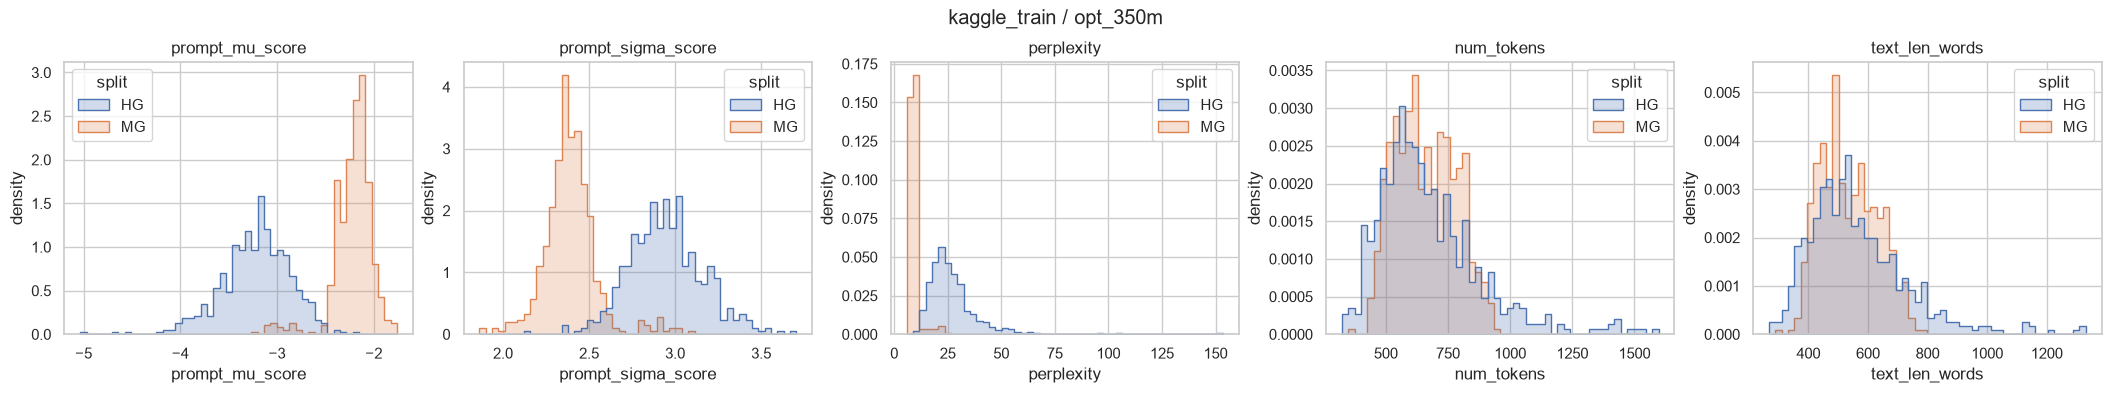

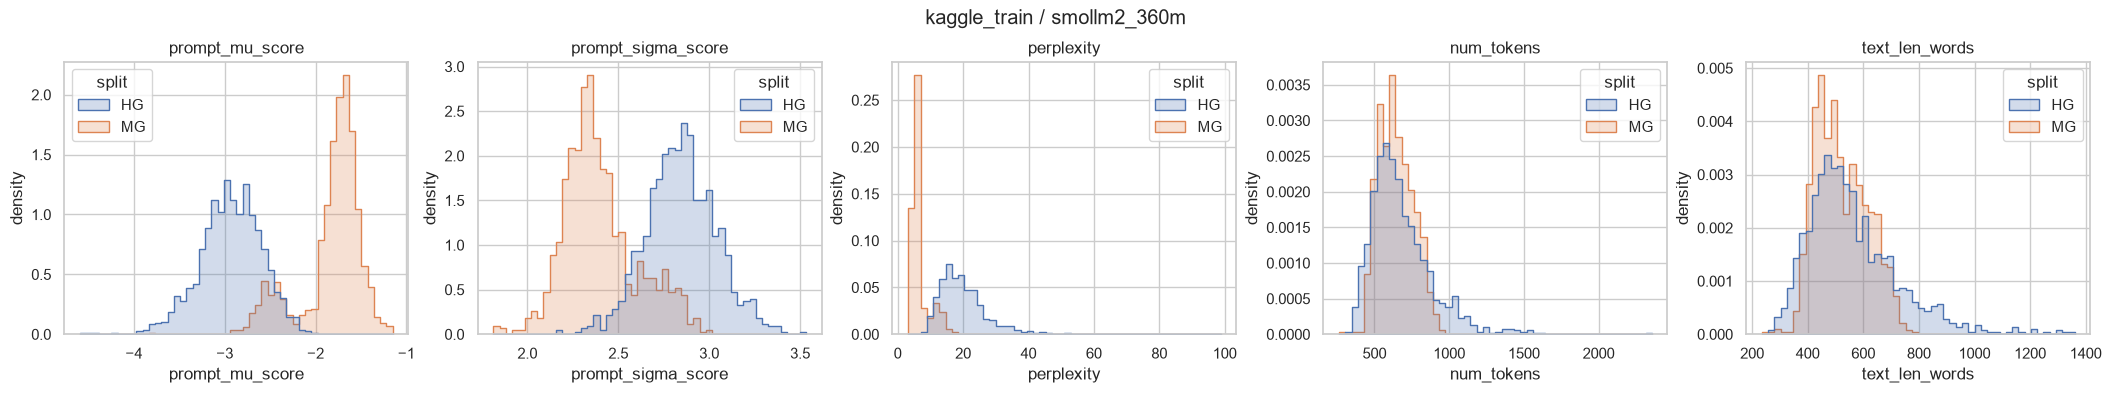

In [7]:
for dataset, model in plot_df[["dataset", "model"]].drop_duplicates().itertuples(index=False):
    plot_experiment_metric_row(plot_df, dataset, model, selected_metrics)

## Numeric Summary

Use this table to compare central tendency and spread alongside the plots.

In [8]:
plot_df.groupby(["dataset", "model", "split"])[selected_metrics].describe().round(4)

prompt_mu_score                          \
                                          count    mean     std     min   
dataset      model        split                                           
kaggle_train opt_350m     HG              570.0 -3.2184  0.3552 -5.0348   
                          MG              570.0 -2.2191  0.2056 -3.2187   
             smollm2_360m HG             1240.0 -2.9339  0.3401 -4.5929   
                          MG             1240.0 -1.8287  0.3408 -3.7971   

                                                                 \
                                    25%     50%     75%     max   
dataset      model        split                                   
kaggle_train opt_350m     HG    -3.4179 -3.1902 -2.9831 -2.1977   
                          MG    -2.2998 -2.1921 -2.0951 -1.7602   
             smollm2_360m HG    -3.1448 -2.9268 -2.6966 -2.0120   
                          MG    -1.9139 -1.7416 -1.6189 -1.1497   

                                prompt_sigma_score                          \
                                             count    mean     std     min   
dataset      model        split                                              
kaggle_train opt_350m     HG                 570.0  2.9453  0.2137  2.1474   
                          MG                 570.0  2.3912  0.1547  1.8632   
             smollm2_360m HG                1240.0  2.8450  0.1926  2.1707   
                          MG                1240.0  2.3976  0.2022  1.8123   

                                                                perplexity  \
                                    25%     50%     75%     max      count   
dataset      model        split                                              
kaggle_train opt_350m     HG     2.8051  2.9386  3.0781  3.7033      570.0   
                          MG     2.3119  2.3810  2.4576  3.1007      570.0   
             smollm2_360m HG     2.7166  2.8441  2.9747  3.5320     1240.0   
                          MG     2.2631  2.3593  2.4989  2.9999     1240.0   

                                                                             \
                                    mean      std     min      25%      50%   
dataset      model        split                                               
kaggle_train opt_350m     HG     26.7622  11.7089  9.0045  19.7482  24.2945   
                          MG      9.4241   2.4432  5.8138   8.1259   8.9543   
             smollm2_360m HG     19.9868   7.8373  7.4780  14.8291  18.6671   
                          MG      6.6573   2.9241  3.1574   5.0477   5.7064   

                                                   num_tokens            \
                                     75%       max      count      mean   
dataset      model        split                                           
kaggle_train opt_350m     HG     30.5040  153.6616      570.0  668.8614   
                          MG      9.9723   24.9955      570.0  658.7702   
             smollm2_360m HG     23.2155   98.7827     1240.0  677.4661   
                          MG      6.7792   44.5696     1240.0  642.7758   

                                                                         \
                                      std    min     25%    50%     75%   
dataset      model        split                                           
kaggle_train opt_350m     HG     204.7284  323.0  533.25  623.5  761.00   
                          MG     120.7135  365.0  560.00  650.0  753.75   
             smollm2_360m HG     207.8623  319.0  538.00  634.0  772.25   
                          MG     114.2165  263.0  551.00  631.5  724.25   

                                        text_len_words                      \
                                    max          count      mean       std   
dataset      model        split                                              
kaggle_train opt_350m     HG     1597.0          570.0  561.9386  163.4494   
                        

## Selected-Token Similarity Scatter

For each text, compute the mean and standard deviation of the selected token similarity. The selected token is the first `top_logprobs` candidate for each position, i.e. the model's most probable token candidate. Each scatter point is one text; `split` is the class label.

In [ ]:
def discover_similarity_files(processed_root: Path) -> list[Path]:
    return sorted(processed_root.glob("*/*/token_similarities/*.parquet"))


def selected_token_similarity_stats(row: pd.Series) -> dict[str, float | int | str | None]:
    selected_similarities = []
    for token in row["token_similarities"]:
        top_logprobs = token.get("top_logprobs")
        if top_logprobs is None or len(top_logprobs) == 0:
            continue
        similarity = top_logprobs[0].get("similarity_to_gt")
        if similarity is not None:
            selected_similarities.append(float(similarity))

    stats = {
        "id": int(row["id"]),
        "dataset": row["dataset"],
        "model": row["model"],
        "experiment_name": row["experiment_name"],
        "split": row["split"],
        "selected_similarity_count": len(selected_similarities),
        "selected_similarity_mean": None,
        "selected_similarity_std": None,
    }
    if selected_similarities:
        series = pd.Series(selected_similarities, dtype="float64")
        stats["selected_similarity_mean"] = float(series.mean())
        stats["selected_similarity_std"] = float(series.std(ddof=0))
    return stats


def load_selected_similarity_stats(processed_root: Path) -> pd.DataFrame:
    rows = []
    paths = discover_similarity_files(processed_root)
    for path in tqdm(paths, desc="Similarity files", unit="file"):
        frame = pd.read_parquet(path)
        row_iter = frame.iterrows()
        rows.extend(
            selected_token_similarity_stats(row)
            for _, row in tqdm(row_iter, total=len(frame), desc=path.parent.parent.name, unit="text", leave=False)
        )
    if not rows:
        raise FileNotFoundError(f"No token similarity files found under {processed_root}")
    return pd.DataFrame(rows).dropna(subset=["selected_similarity_mean", "selected_similarity_std"])


similarity_stats_df = load_selected_similarity_stats(PROCESSED_ROOT)
similarity_stats_df.head()

In [ ]:
def plot_similarity_scatter(data: pd.DataFrame, *, alpha: float = 0.65) -> None:
    for dataset, model in data[["dataset", "model"]].drop_duplicates().itertuples(index=False):
        experiment_df = data[(data["dataset"] == dataset) & (data["model"] == model)]
        fig, axis = plt.subplots(figsize=(7, 5), constrained_layout=True)
        sns.scatterplot(
            data=experiment_df,
            x="selected_similarity_mean",
            y="selected_similarity_std",
            hue="split",
            alpha=alpha,
            s=35,
            edgecolor=None,
            ax=axis,
        )
        axis.set_title(f"Selected-token similarity: {dataset} / {model}")
        axis.set_xlabel("Mean selected-token similarity")
        axis.set_ylabel("Std selected-token similarity")
        axis.legend(title="split")
        plt.show()


plot_similarity_scatter(similarity_stats_df)